# Neural Network Framework — Training on XOR & MNIST

In **Modules 1 through 4**, we built the low-level computational engine from scratch:
forward Directed Acyclic Graphs (DAGs), scalar and tensor reverse-mode autograd,
Vector-Jacobian Products (VJPs), and automated reverse broadcasting.

Now, we introduce the **high-level, modular abstractions** that make deep learning
practical and composable:

* **`nn.Module` & `nn.Parameter`**: Automated recursive parameter registration and
  management.
* **Layers & Containers**: `Linear`, `ReLU`, and `Sequential`.
* **Loss Functions & Optimizers**: `MSELoss`, `CrossEntropyLoss`, and `Adam`.
* **Data Pipelines**: `TensorDataset` and `DataLoader` for shuffling and batching.

In this notebook, we put our from-scratch framework to the test on two classic
milestones: solving the non-linear **XOR problem**, and training a classifier
on the real-world **MNIST dataset**.

---

# Notebook Roadmap & Experiments

| # | Experiment | Architecture & Loss | Key Milestone |
|:---:|:---|:---|:---|
| **01** | **The Non-Linear XOR Problem** | `Sequential(Linear(2, 8), ReLU, Linear(8, 1))` + `MSELoss` | Proves hidden representations and non-linear activations break linear separability barriers, converging to loss $< 0.01$. |
| **02** | **MNIST Handwritten Digit Classification** | `Sequential(Linear(784, 128), ReLU, Linear(128, 10))` + `CrossEntropyLoss` | Trains a full neural network on 784-dimensional pixel arrays with batched data loading, validation metrics, and live drawing inference. |

---

###  The Canonical Deep Learning Training Loop

Both experiments follow the standard training idiom:

```python
for batch_x, batch_y in train_loader:
    optimizer.zero_grad()           # 1. Reset parameter gradients
    logits = model(batch_x)         # 2. Forward pass through Module DAG
    loss = criterion(logits, batch_y) # 3. Evaluate loss
    loss.backward()                 # 4. Reverse-mode autograd (VJP)
    optimizer.step()                # 5. Parameter update (Adam / SGD)
```

In [1]:
import utorch as ut
import utorch.nn as nn
from utorch.utils.data import TensorDataset, DataLoader
from utorch.utils import show_drawing_canvas
import matplotlib.pyplot as plt
import numpy as np


In [2]:
# XOR dataset
X = ut.Tensor([[0.0, 0.0], [0.0, 1.0], [1.0, 0.0], [1.0, 1.0]])
y = ut.Tensor([[0.0], [1.0], [1.0], [0.0]])

# 2-layer MLP
model = nn.Sequential(
    nn.Linear(2, 8),
    nn.ReLU(),
    nn.Linear(8, 1),
)

criterion = nn.MSELoss()
optimizer = nn.SGD(model.parameters(), lr=0.05)
losses = []
n_steps = 80

for epoch in range(n_steps):
    optimizer.zero_grad()
    loss = criterion(model(X), y)
    loss.backward()
    losses.append(loss.value)
    optimizer.step()

print(f"Final XOR Loss: {loss.value:.5f}")  # 0.00000


Final XOR Loss: 0.19231


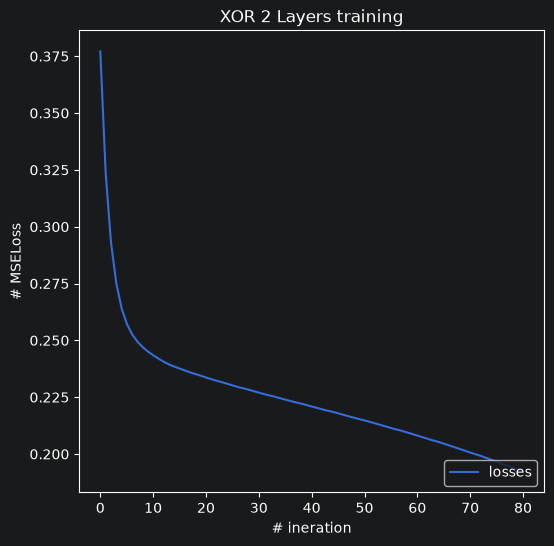

In [3]:
plt.figure(figsize=[6, 6])
x_axis = np.linspace(0, n_steps, n_steps)
plt.plot(x_axis, losses, label='losses');
plt.xlabel('# ineration')
plt.ylabel('# MSELoss')
plt.title('XOR 2 Layers training')
plt.legend(loc="lower right");


In [4]:
def load_mnist(
    n_samples: int = 10000,
) -> tuple[TensorDataset, TensorDataset]:
    """Load MNIST dataset normalized to [0.0, 1.0] as TensorDatasets.

    Returns:
        (train_dataset, test_dataset)
    """
    from sklearn.datasets import fetch_openml

    print("Loading MNIST digits...")
    import ssl
    ssl._create_default_https_context = ssl._create_unverified_context

    mnist = fetch_openml("mnist_784", version=1, as_frame=False, parser="auto")
    X = mnist.data[:n_samples].astype(np.float64) / 255.0
    y_raw = mnist.target[:n_samples].astype(int)

    # Convert targets to one-hot encoding for CrossEntropy / MSE
    y_one_hot = np.eye(10)[y_raw]

    # 80/20 train/test split
    split = int(0.8 * n_samples)
    train_ds = TensorDataset(X[:split], y_one_hot[:split])
    test_ds = TensorDataset(X[split:], y_one_hot[split:])
    return train_ds, test_ds


In [5]:
# 1. Load data
train_ds, test_ds = load_mnist(n_samples=5000)
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=1, shuffle=False)

Loading MNIST digits...


In [62]:
model = nn.Sequential(
    nn.Linear(784, 128),
    nn.ReLU(),
    nn.Linear(128, 10),
)

criterion = nn.CrossEntropyLoss()
optimizer = nn.SGD(model.parameters(), lr=0.005)


In [63]:

def train_model(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    criterion: nn.Module,
    optimizer: nn.Optimizer,
    epochs: int = 10,
) -> dict[str, list[float]]:
    """Train a neural network with automated validation and history tracking.

    Args:
        model: nn.Module instance to train.
        train_loader: DataLoader yielding training batches.
        val_loader: DataLoader yielding validation batches.
        criterion: Loss module (e.g. nn.CrossEntropyLoss, nn.MSELoss).
        optimizer: Optimizer instance (e.g. nn.Adam, nn.SGD).
        epochs: Number of complete passes over the training set.

    Returns:
        History dictionary containing lists of train/val loss and accuracy:
        {'train_loss': [...], 'val_loss': [...], 'train_acc': [...], 'val_acc': [...]}

    Examples:
        ```python
        history = train_model(
            model=model,
            train_loader=train_loader,
            val_loader=val_loader,
            criterion=criterion,
            optimizer=optimizer,
            epochs=5,
        )
        plot_learning_curves(history)
        ```
    """
    history: dict[str, list[float]] = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
    }

    for epoch in range(1, epochs + 1):
        # =====================================================================
        # 1. Training Phase
        # =====================================================================
        epoch_train_loss = 0.0
        train_correct = 0
        train_total = 0

        for batch_x, batch_y in train_loader:
            optimizer.zero_grad()
            logits = model(batch_x)
            loss = criterion(logits, batch_y)
            loss.backward()
            optimizer.step()

            batch_size = batch_x.shape[0]
            epoch_train_loss += float(loss.value) * batch_size

            # Compute training accuracy
            preds = np.argmax(logits.value, axis=-1)
            if batch_y.shape == logits.shape:
                targets = np.argmax(batch_y.value, axis=-1)
            else:
                targets = batch_y.value.astype(int)
            train_correct += int(np.sum(preds == targets))
            train_total += batch_size

        avg_train_loss = epoch_train_loss / train_total
        avg_train_acc = train_correct / train_total

        # =====================================================================
        # 2. Validation Phase (Inference only, no backprop)
        # =====================================================================
        epoch_val_loss = 0.0
        val_correct = 0
        val_total = 0

        for val_x, val_y in val_loader:
            val_logits = model(val_x)
            v_loss = criterion(val_logits, val_y)

            val_batch_size = val_x.shape[0]
            epoch_val_loss += float(v_loss.value) * val_batch_size

            val_preds = np.argmax(val_logits.value, axis=-1)
            if val_y.shape == val_logits.shape:
                val_targets = np.argmax(val_y.value, axis=-1)
            else:
                val_targets = val_y.value.astype(int)
            val_correct += int(np.sum(val_preds == val_targets))
            val_total += val_batch_size

        avg_val_loss = epoch_val_loss / val_total
        avg_val_acc = val_correct / val_total

        # Record metrics history
        history["train_loss"].append(avg_train_loss)
        history["val_loss"].append(avg_val_loss)
        history["train_acc"].append(avg_train_acc)
        history["val_acc"].append(avg_val_acc)

        print(
            f"Epoch {epoch:02d}/{epochs:02d} | "
            f"Train Loss: {avg_train_loss:.4f}, Acc: {avg_train_acc*100:.1f}% | "
            f"Val Loss: {avg_val_loss:.4f}, Acc: {avg_val_acc*100:.1f}%"
        )

    return history


def plot_learning_curves(history: dict[str, list[float]]) -> None:
    """Plot training and validation loss & accuracy curves side-by-side."""
    epochs = range(1, len(history["train_loss"]) + 1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

    # Loss Curve
    ax1.plot(
        epochs, history["train_loss"], "o-", label="Train Loss",
        color="#EE4C2C", lw=2,
    )
    ax1.plot(
        epochs, history["val_loss"], "s--", label="Val Loss",
        color="#2A2F35", lw=2,
    )
    ax1.set_title("Cross-Entropy Loss vs. Epochs", fontsize=11, fontweight="bold")
    ax1.set_xlabel("Epoch", fontsize=10)
    ax1.set_ylabel("Loss", fontsize=10)
    ax1.grid(True, linestyle=":", alpha=0.6)
    ax1.legend(frameon=True)

    # Accuracy Curve
    ax2.plot(
        epochs, [a * 100 for a in history["train_acc"]],
        "o-", label="Train Acc", color="#1F77B4", lw=2,
    )
    ax2.plot(
        epochs, [a * 100 for a in history["val_acc"]],
        "s--", label="Val Acc", color="#2CA02C", lw=2,
    )
    ax2.set_title("Accuracy (%) vs. Epochs", fontsize=11, fontweight="bold")
    ax2.set_xlabel("Epoch", fontsize=10)
    ax2.set_ylabel("Accuracy (%)", fontsize=10)
    ax2.grid(True, linestyle=":", alpha=0.6)
    ax2.legend(frameon=True)

    plt.tight_layout()
    plt.show()


Epoch 01/200 | Train Loss: 2.2904, Acc: 15.4% | Val Loss: 2.2562, Acc: 25.5%
Epoch 02/200 | Train Loss: 2.2331, Acc: 29.4% | Val Loss: 2.1983, Acc: 34.3%
Epoch 03/200 | Train Loss: 2.1713, Acc: 40.4% | Val Loss: 2.1322, Acc: 49.2%
Epoch 04/200 | Train Loss: 2.1006, Acc: 52.7% | Val Loss: 2.0560, Acc: 58.2%
Epoch 05/200 | Train Loss: 2.0201, Acc: 60.5% | Val Loss: 1.9699, Acc: 63.2%
Epoch 06/200 | Train Loss: 1.9300, Acc: 64.4% | Val Loss: 1.8751, Acc: 66.7%
Epoch 07/200 | Train Loss: 1.8318, Acc: 67.2% | Val Loss: 1.7731, Acc: 69.4%
Epoch 08/200 | Train Loss: 1.7273, Acc: 69.5% | Val Loss: 1.6666, Acc: 71.0%
Epoch 09/200 | Train Loss: 1.6194, Acc: 71.7% | Val Loss: 1.5583, Acc: 72.4%
Epoch 10/200 | Train Loss: 1.5114, Acc: 73.3% | Val Loss: 1.4520, Acc: 74.2%
Epoch 11/200 | Train Loss: 1.4066, Acc: 74.4% | Val Loss: 1.3508, Acc: 75.1%
Epoch 12/200 | Train Loss: 1.3081, Acc: 75.9% | Val Loss: 1.2574, Acc: 76.5%
Epoch 13/200 | Train Loss: 1.2176, Acc: 77.8% | Val Loss: 1.1724, Acc: 77.9%

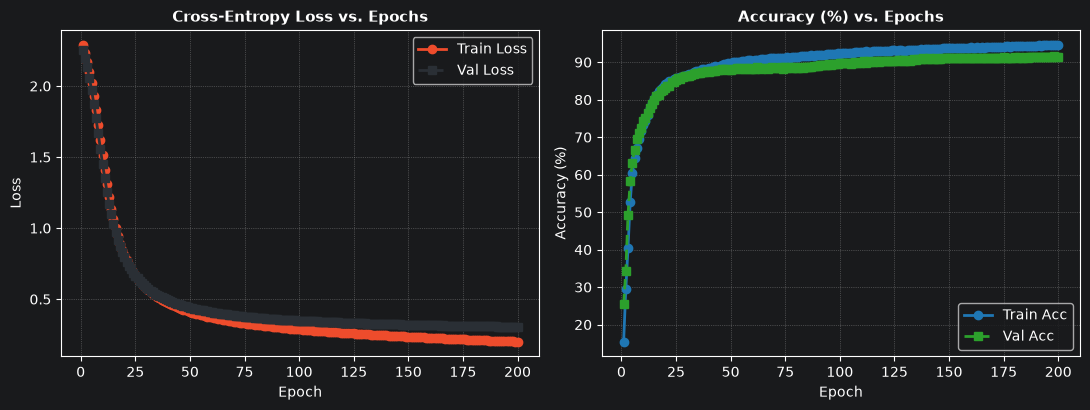

In [64]:
# 1. Run training with validation tracking
history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=test_loader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=200,
)

# 2. Render side-by-side training & validation curves
plot_learning_curves(history)


In [65]:
show_drawing_canvas()

In [66]:
drawn_digit = np.array([0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.02,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.5,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.5,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.5,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.5,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.5,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.5,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.5,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.5,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.5,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,0.5,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.5,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0]).reshape(1, 784)

In [67]:
pred_logits = model(ut.Tensor(drawn_digit))
predicted_class = int(np.argmax(pred_logits.value))
print(f"Predicted Digit: {predicted_class}")
pred_logits.value

Predicted Digit: 4


array([[-5.62855376, -0.99949284, -4.73317114,  0.33260029,  4.7787065 ,
         2.39386594, -1.06858567,  0.98922202,  1.50798677,  1.51081812]])

In [68]:
model.parameters()

[ut.Tensor('bias', value=[ 0.00549317  0.09890369  0.06716606  0.03983332  0.00651003 -0.03759018
   0.02933437  0.02766613  0.04996095  0.01306363  0.01746381 -0.01620235
  -0.00908217  0.08931584  0.04020482 -0.02753519 -0.00230549  0.03337034
  -0.05408012  0.00558574 -0.00808368  0.00688869 -0.02794718  0.01328653
   0.03191349  0.03699229  0.00354712 -0.01187078 -0.02249217  0.07464888
   0.07437085  0.09608713  0.01568382 -0.05437661  0.009616    0.04354498
  -0.01984074 -0.01022372  0.0837856   0.00482276  0.07138005 -0.02561453
   0.02523395  0.03445408 -0.00356738  0.08010765  0.09937369  0.02010756
   0.13177104  0.01931561  0.04855961 -0.07887634  0.03865674 -0.00916584
   0.03028491 -0.05143141 -0.0356877  -0.04257433  0.06249911  0.01282852
   0.0167316   0.06979032  0.0543268  -0.01290116 -0.01446742  0.05281102
   0.0402322   0.01072859 -0.00117659  0.04915931  0.0094965  -0.00013771
   0.0139129   0.01605026 -0.01485302  0.00821581 -0.00957681 -0.00517134
   0.00225167 